# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

This notebook analyzes historical luxury watch auction prices for Rolex, Cartier, and Omega watches sold through Sotheby's and Bonhams between 2021 and 2026.

We use Python to prepare the data, calculate descriptive statistics, fit prediction models, and evaluate whether predictions can support watch purchasing decisions.

For reproducibility, we record the Python environment, package versions, and random seed. Data provenance and file checksums are documented in data/README.md.


In [3]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Reproducibility
SEED = 20261024
np.random.seed(SEED)

# Project folders
DATA_DIR = Path("data")
FIG_DIR = Path("fig")
FIG_DIR.mkdir(exist_ok=True)

# Environment information
print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Random seed:", SEED)


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Pandas: 3.1.0
NumPy: 2.5.4
Matplotlib: 3.11.2
Random seed: 20261024


In [ ]:
## Question

Can a regression model using watch characteristics predict realized auction sale prices more accurately than a simple brand-median baseline?

### Prediction Target

The target variable is the realized auction sale price in U.S. dollars (USD) for an individual Rolex, Cartier, or Omega wristwatch sold at Sotheby's or Bonhams.

### Prediction Time

Predictions are intended to be made before an auction sale, using watch characteristics available at that time.

### Available Inputs

Potential predictors include:

- Watch brand
- Model or reference
- Approximate production year or watch age
- Case material
- Movement type
- Other characteristics known before the auction

### Evaluation Period

We propose training on sales from 2021–2023, validating on 2024 sales, and evaluating on2025–2026 sales.

The chronological test period has prior exposure from preliminary random-split development, so it cannot be described as completely untouched.

### Baseline and Evaluation Metric

Our baseline predicts the median sale price for each brand, calculated from training data only.

We will compare this baseline with a regression model using Mean Absolute Error (MAE), measured in USD.

### Decision Supported

Predicted prices will help identify watches worth further purchasing investigation. The model will support screening decisions rather
than automatically determine maximum bids.

Overestimating a watch's value could contribute to an unprofitable purchase. Underestimating its value could cause us to miss a potentially attractive opportunity.

### Layer Diagram

![Luxury Watch Prediction and Decision Layers](fig/layers.png)


## Data

Our dataset contains 4,664 eligible individual wristwatch auction sales for Rolex, Cartier, and Omega at Sotheby's and Bonhams, collected through the ALT/FNData API.

The observed sales span February 5, 2021, through July 28, 2026. The target variable is realized auction sale price in USD.

The dataset was collected using capped, sale-date-ordered API requests, so it is not a random sample of the entire luxury watch market.

This section examines the raw price distribution, descriptive statistics, and missing values before fitting prediction models.

In [20]:
import pandas as pd
from pathlib import Path

data_path = Path("data/expanded_pull_eligible.csv")

df = pd.read_csv(data_path, low_memory=False)

print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())



Rows: 4664
Columns: 212


,record_id,source_response_file,source_row_index,source_record_sha256,auction_lot,auction_no,auction_type,bracelet_material,buckle_clasp,case_diameter,...,flag_multiple_or_mixed_lot,flag_attribution_ambiguity,flag_conflicting_specifications,flag_invalid_date,flag_production_year_after_sale,flag_nonpositive_price,flag_duplicate_lot_url,flag_conversion_review,flag_historical_maker_attribution,flag_other_maker_movement
0,cartier_bonhams_2021_o000000_l050.json#0,cartier_bonhams_2021_o000000_l050.json,0,3a1310e02cf1fae279b1a1237478e83399ab358e822ec1...,520,26656,Live,Stainless Steel,NaN,35mm,...,False,False,False,False,False,False,False,False,False,False
1,cartier_bonhams_2021_o000000_l050.json#1,cartier_bonhams_2021_o000000_l050.json,1,9c7b4ae1814e3ffe155a21d8567b8103f03c39362e1aa4...,521,26656,Live,Stainless Steel,NaN,25mm,...,False,False,False,False,False,False,False,False,False,False
2,cartier_bonhams_2021_o000000_l050.json#2,cartier_bonhams_2021_o000000_l050.json,2,71616b26f0ed192efd309b22881f54ba1e85e286e8ecef...,523,26656,Live,White Gold,NaN,23mm,...,False,False,False,False,False,False,False,False,False,False
3,cartier_bonhams_2021_o000000_l050.json#3,cartier_bonhams_2021_o000000_l050.json,3,1593dd311d680494f96438d3c19b7e6a3f2ae4da35984d...,524,26656,Live,Pink Gold,NaN,41mm,...,False,False,False,False,False,False,False,False,False,False
4,cartier_bonhams_2021_o000000_l050.json#4,cartier_bonhams_2021_o000000_l050.json,4,e9e8a2b0178196eb821e2cabf81d771a07552c8e220678...,578,26656,Live,Leather,NaN,NaN,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
### Summary Statistics by Brand

In [19]:
summary = df.groupby("designer")["usd_price_decimal_num"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Min="min",
    Max="max"
)

display(summary.round(2))


,Count,Mean,Median,Std_Dev,Min,Max
designer,,,,,,
Cartier,1594,20678.04,7035.98,67377.52,254.53,1521791.71
Omega,1284,5726.89,2682.80,14977.25,149.39,359723.29
Rolex,1786,29476.39,12202.87,102751.40,152.36,3141173.09


In [ ]:
### What the results tell us
- Rolex has the highest typical auction price, with a median of $12,203.
- Cartier ranks second, with a median of $7,036.
- Omega has the lowest median, at $2,683.
- All three distributions are right-skewed, as their means are substantially higher than their medians.
- There are extreme high-price observations, particularly among Rolex watches, where the maximum exceeds $3 million.

The descriptive statistics show substantial differences in auction sale prices across the three watch brands. 
Rolex has the highest median price ($12,203), followed by Cartier ($7,036) and Omega ($2,683).

For all three brands, mean prices are considerably higher than median prices, suggesting right-skewed distributions influenced by 
exceptionally expensive watches. Rolex also exhibits the greatest price variability, with a standard deviation of approximately $102,751.

These findings support using brand as a predictor and comparing our regression model against a brand-median baseline. 
The next step is to examine the price distributions visually using a boxplot with a logarithmic price axis.

In [ ]:
### Figure 1. Distribution of Auction Sale Prices by Brand

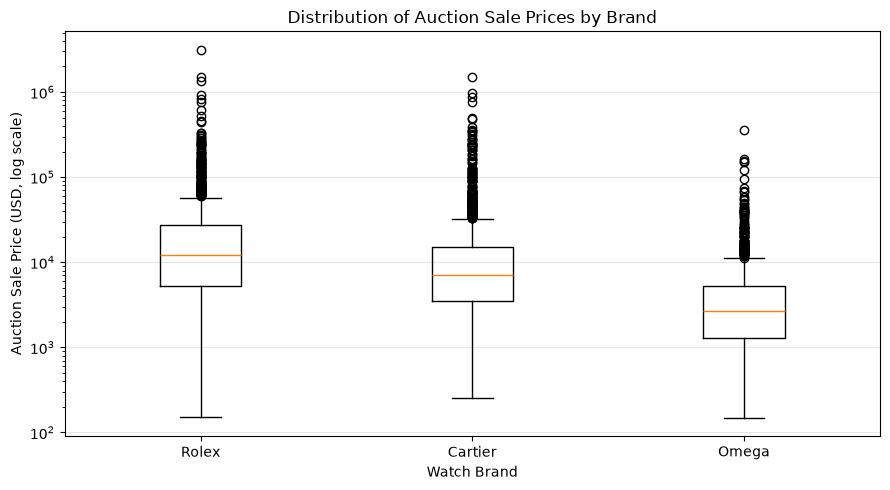

In [22]:
import matplotlib.pyplot as plt
from pathlib import Path

brands = ["Rolex", "Cartier", "Omega"]

prices = [
    df.loc[
        (df["designer"] == brand) &
        (df["usd_price_decimal_num"] > 0),
        "usd_price_decimal_num"
    ].dropna()
    for brand in brands
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(prices, tick_labels=brands)

ax.set_yscale("log")
ax.set_xlabel("Watch Brand")
ax.set_ylabel("Auction Sale Price (USD, log scale)")
ax.set_title("Distribution of Auction Sale Prices by Brand")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save chart in the fig folder
Path("fig").mkdir(exist_ok=True)
fig.savefig("fig/watch_price_boxplot.png", dpi=300)

# Display chart without extra text output
plt.show()


In [ ]:
The boxplot shows substantial variation in auction sale prices across Rolex, Cartier, and Omega watches. 
Rolex has the highest median price, followed by Cartier and Omega.
All three brands exhibit numerous high-price outliers, consistent with the large differences between their mean and median prices.

The logarithmic price scale allows the distributions to be compared despite the wide range of auction prices.
These results suggest that brand is an important predictor, but brand alone may not explain the substantial variation within each group. 
Additional watch characteristics, such as model, production year, and case material, may improve prediction accuracy.

In [ ]:
### Missing Data

In [23]:
model_columns = [
    "designer",
    "model",
    "sale_date",
    "production_year",
    "case_material",
    "movement",
    "usd_price_decimal_num"
]

missing_model = (
    df[model_columns]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(missing_model.round(2))



case_material            39.11
movement                 28.24
model                    12.03
production_year           7.42
designer                  0.00
sale_date                 0.00
usd_price_decimal_num     0.00
dtype: float64

In [ ]:
The missing-data analysis shows that the target variable, auction sale price in USD, is complete across all 4,664 eligible observations. Brand and sale date also have no missing values, supporting brand-based comparisons and 
chronological data splitting.

Among candidate predictors, case material has the highest missingness (39.11%), followed by movement (28.24%), 
model (12.03%), and production year (7.42%). These gaps may limit the usefulness of certain watch characteristics in predicting auction prices.

Rather than removing all incomplete records, we will compare simpler models against models that explicitly handle missing predictor values. 
Any preprocessing choices will be developed using training data and evaluated on validation data to avoid leakage.

In [17]:
import hashlib

file_path = Path("data/expanded_pull_eligible.csv")
sha256 = hashlib.sha256(file_path.read_bytes()).hexdigest()

print("SHA-256:", sha256)


SHA-256: 008790f43b08461b27b01cd496d5d2b5c7e8c5214bb609bf5a53579aec21109c


In [ ]:
## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
